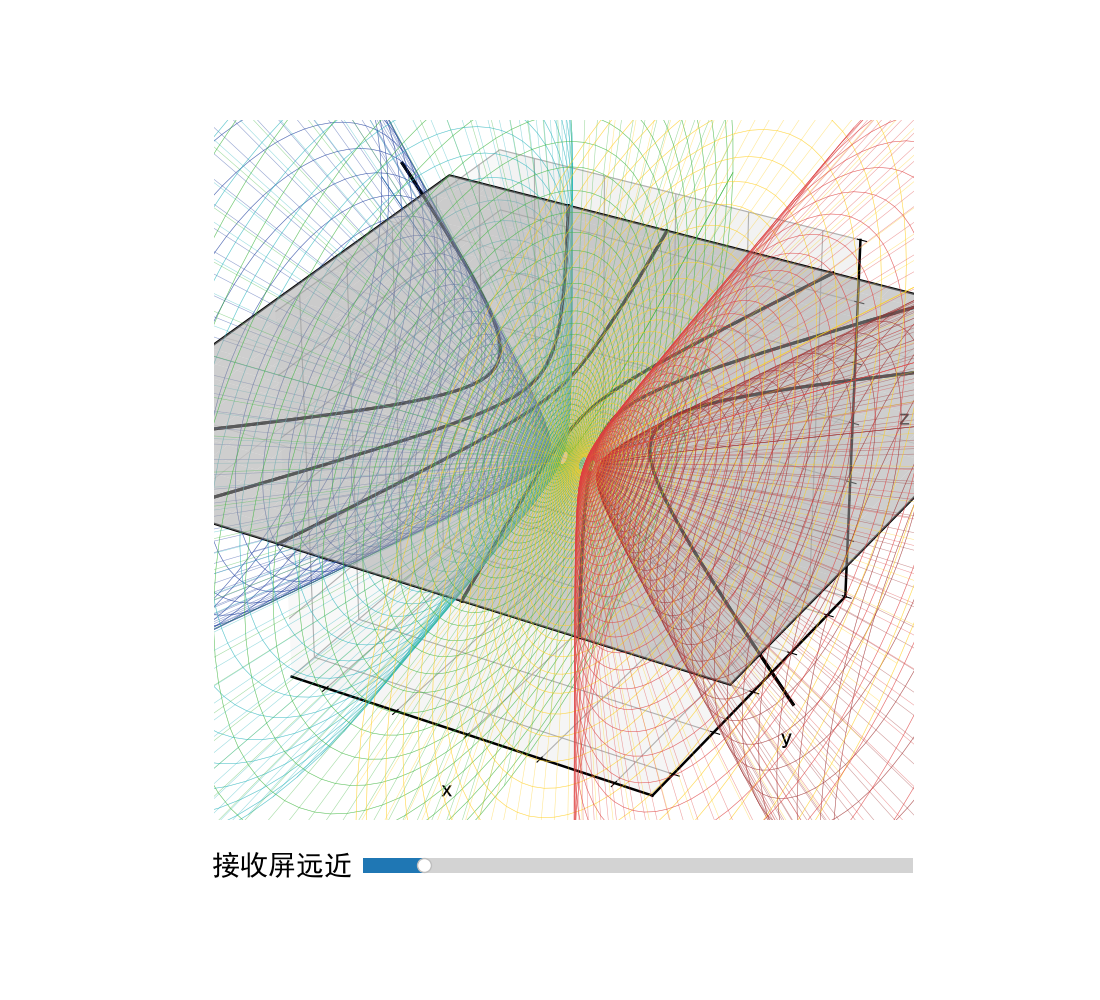

In [3]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.widgets import Slider

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# =====参数=====
d = 0.020
lam = 0.0025
c = d / 2

m_list = [-6, -4, -2, 2, 4, 6]
color_list = ["#2040a0", "#30b8c0", "#40b840", "#ffd020", "#e04040", "#a03030"]

u = np.linspace(0, 2 * np.pi, 80)
v = np.linspace(0.2, 3.5, 80)
U, V = np.meshgrid(u, v)

# 画布：主3D图 + 下方滑块区域
fig = plt.figure(figsize=(11, 10))
ax = fig.add_subplot(111, projection='3d')
fig.subplots_adjust(bottom=0.18)  # 留出滑块空间

# 滑块轴
ax_slider = fig.add_axes([0.33, 0.12, 0.50, 0.03])
slider = Slider(
    ax=ax_slider,
    label="接收屏远近",
    valmin=0.015,
    valmax=0.06,
    valinit=0.02
)
# 隐藏滑块右侧数值文本
slider.valtext.set_visible(False)
# 设置滑块标签文字大小
slider.label.set_fontsize(20)

screen_half = 0.09

# 预先绘制固定的双曲面（不动）
surface_handles = []
for idx, m in enumerate(m_list):
    delta = m * lam
    a = delta / 2
    if np.abs(a) >= c:
        continue
    b = np.sqrt(c**2 - a**2)

    X1 = a * np.cosh(V)
    Y1 = b * np.sinh(V) * np.cos(U)
    Z1 = b * np.sinh(V) * np.sin(U)

    wf1 = ax.plot_wireframe(X1, Y1, Z1, color=color_list[idx], alpha=0.5, linewidth=0.4)
    wf2 = ax.plot_wireframe(X1, Y1, -Z1, color=color_list[idx], alpha=0.5, linewidth=0.4)
    surface_handles.append((wf1, wf2))

# 用于保存会更新的图元：屏幕面、边框、网格、条纹
screen_artists = []

def update_screen(D_screen):
    # 清除旧的屏幕相关对象
    for art in screen_artists:
        art.remove()
    screen_artists.clear()

    # 绘制接收屏平面
    xx, yy = np.meshgrid(np.linspace(-screen_half, screen_half, 30),
                         np.linspace(-screen_half, screen_half, 30))
    zz_plane = D_screen * np.ones_like(xx)
    surf = ax.plot_surface(xx, yy, zz_plane, color="#d9d9d9", alpha=0.55)
    screen_artists.append(surf)

    # 屏幕边框
    border_x = np.array([-screen_half, screen_half, screen_half, -screen_half, -screen_half])
    border_y = np.array([-screen_half, -screen_half, screen_half, screen_half, -screen_half])
    border_z = np.full_like(border_x, D_screen)
    line_border, = ax.plot(border_x, border_y, border_z, color="black", lw=1.6)
    screen_artists.append(line_border)

    # 屏幕内部网格线
    wf_scr = ax.plot_wireframe(xx, yy, zz_plane, color="#888888",
                               alpha=0.35, linewidth=0.5, rstride=6, cstride=6)
    screen_artists.append(wf_scr)

    # 绘制各级条纹交线
    for idx, m in enumerate(m_list):
        delta = m * lam
        a = delta / 2
        if np.abs(a) >= c:
            continue
        b = np.sqrt(c**2 - a**2)
        z0 = D_screen
        y_line = np.linspace(-screen_half, screen_half, 600)
        x_sq = a**2 * (1 + (y_line**2 + z0**2) / b**2)
        mask_valid = x_sq > 0
        y_use = y_line[mask_valid]
        x_pos = np.sqrt(x_sq[mask_valid])
        x_neg = -np.sqrt(x_sq[mask_valid])

        lp, = ax.plot(x_pos, y_use, z0, color='black', lw=2.2)
        ln, = ax.plot(x_neg, y_use, z0, color='black', lw=2.2)
        screen_artists.append(lp)
        screen_artists.append(ln)

    fig.canvas.draw_idle()

# 初始绘制
update_screen(slider.val)
slider.on_changed(update_screen)

# ==========视角与坐标轴设置============
ax.view_init(elev=30, azim=-60)
ax.set_box_aspect([1, 1, 1])

ax.set_xlabel('x', fontsize=18)
ax.set_ylabel('y', fontsize=18)
ax.set_zlabel('z', fontsize=18)

ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_zticklabels([])

for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis.line.set_linewidth(1.8)

ax.set_xlim(-0.05, 0.05)
ax.set_ylim(-0.05, 0.05)
ax.set_zlim(-0.06, 0.06)

plt.show()

